# History timeline: when is each action type recorded?

Post-interim follow-up (experiment **E01** in `docs/EXPERIMENT_LOG.md`, results in `docs/FINDINGS.md` section 7).

**Question.** The interim feedback pointed out that history looks like an inverted funnel: carts (11.5M) and orders (6.8M) outnumber clicks (8.3M), although in e-commerce clicks usually outnumber carts 5-10:1 and carts outnumber orders 3-5:1. What happens to each action type as we trace history further back in time?

**Method.** `history_time_list` stores gaps in seconds: an initial 0, one gap per transition, and a final gap from the last action to the current search. The time from action *i* to the search is the sum of all gaps after it:

```
history:  ORD ──── CART ──── CLICK ── CLICK ── [search]
gaps:         200 d      30 d      1 h      5 min
ORD happened 200 d + 30 d + 1 h + 5 min before the search
```

We stream the full behaviour file (173,831 records, 26.7M actions, about 30 seconds) and count actions per type and per elapsed whole day.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_ROOT = next((p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/interim_eda.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open/clone the repository checkout first.")
if IN_COLAB:
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/drive/MyDrive/BT4222 Group Project/data")
else:
    DATA_DIR = REPO_ROOT / "data"
OUT = REPO_ROOT / "outputs/eda/history_timeline"
OUT.mkdir(parents=True, exist_ok=True)

TYPES = ["CLICK", "CART", "ORD", "FLW"]
MAX_DAY = 400  # elapsed days are capped here; the documented window is one year
pd.options.display.float_format = "{:,.2f}".format

## Count actions by type and days before the search

Per record we also keep the time since the last action (final gap) and whether any click is present, to check what "no clicks" means.

In [2]:
def elapsed_days(gaps):
    # Days from each past action to the search; gaps = [0, g1, ..., gn, gap to search].
    return np.cumsum(gaps[::-1])[::-1][1:] / 86400.0


assert np.allclose(elapsed_days(np.array([0, 10 * 86400, 86400, 0])), [11, 1, 0])  # toy check

counts = {(source, t): np.zeros(MAX_DAY, np.int64) for source in ("all", "query") for t in TYPES}
records = []
with open(DATA_DIR / "user_behavior_data.txt", encoding="utf8") as handle:
    next(handle)
    for line in handle:
        fields = line.rstrip("\r\n").split("\t")
        types = np.array(fields[5].split("_"))
        linked = np.array(fields[3].split("_")) != "-1"  # search-linked action
        gaps = np.array(fields[6].split("_"), dtype=np.int64)
        assert len(gaps) == len(types) + 1
        elapsed = elapsed_days(gaps)
        day = np.minimum(elapsed.astype(int), MAX_DAY - 1)
        for t in TYPES:
            mask = types == t
            np.add.at(counts["all", t], day[mask], 1)
            np.add.at(counts["query", t], day[mask & linked], 1)
        clicks = types == "CLICK"
        records.append((gaps[-1] / 86400.0, clicks.any(), elapsed[clicks].max() if clicks.any() else np.nan))

by_day = pd.DataFrame({f"{s}_{t}": v for (s, t), v in counts.items()}).rename_axis("elapsed_day")
records = pd.DataFrame(records, columns=["days_since_last_action", "has_click", "oldest_click_days"])
by_day.to_csv(OUT / "actions_by_elapsed_day.csv")
print(f"records {len(records):,}; actions {int(by_day.filter(like='all_').to_numpy().sum()):,}")

records 173,831; actions 26,667,260


## Each type stops at a hard cutoff

In [3]:
summary = pd.DataFrame({
    "actions": [by_day[f"all_{t}"].sum() for t in TYPES],
    "last_non_empty_day": [np.nonzero(by_day[f"all_{t}"].to_numpy())[0].max() for t in TYPES],
    "share_search_linked": [by_day[f"query_{t}"].sum() / by_day[f"all_{t}"].sum() for t in TYPES],
}, index=TYPES)
summary

,actions,last_non_empty_day,share_search_linked
CLICK,8298894,13,0.28
CART,11526504,399,0.31
ORD,6817283,364,0.51
FLW,24579,89,0.00


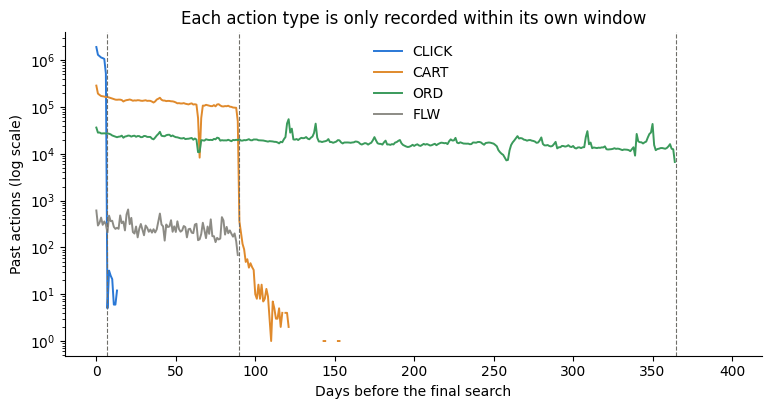

In [4]:
colours = {"CLICK": "#2a78d6", "CART": "#e08a2c", "ORD": "#3a9a5b", "FLW": "#8c8b85"}
fig, ax = plt.subplots(figsize=(9, 4.2))
for t in TYPES:
    ax.plot(by_day.index, by_day[f"all_{t}"].replace(0, np.nan), label=t, color=colours[t], linewidth=1.4)
for edge in (7, 90, 365):
    ax.axvline(edge, color="#6f6e69", linestyle="--", linewidth=0.8)
ax.set(yscale="log", xlabel="Days before the final search", ylabel="Past actions (log scale)",
       title="Each action type is only recorded within its own window")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(OUT / "actions_by_elapsed_day.png", dpi=180, bbox_inches="tight")
plt.show()

## Inside a shared window the funnel is normal

Windows follow the observed cutoffs: clicks up to 7 days, carts and follows up to 90 days, orders up to 365 days.

In [5]:
WINDOWS = [(0, 7), (7, 90), (90, 366)]
rows = []
for lo, hi in WINDOWS:
    part = by_day.iloc[lo:hi]
    row = {"window_days": f"[{lo}, {hi})", **{t: int(part[f"all_{t}"].sum()) for t in TYPES}}
    row["clicks_per_cart"] = row["CLICK"] / row["CART"] if row["CART"] else np.nan
    row["carts_per_order"] = row["CART"] / row["ORD"] if row["ORD"] else np.nan
    rows.append(row)
windows = pd.DataFrame(rows)
windows.to_csv(OUT / "actions_by_window.csv", index=False)
windows

,window_days,CLICK,CART,ORD,FLW,clicks_per_cart,carts_per_order
0,"[0, 7)",8298787,1335157,202822,2651,6.22,6.58
1,"[7, 90)",107,10190143,1833103,21928,0.00,5.56
2,"[90, 366)",0,1203,4781358,0,0.00,0.00


## What "no clicks" means

In [6]:
no_click = ~records.has_click
recent = records.days_since_last_action < 7
print(f"records without any click: {no_click.sum():,} ({no_click.mean():.1%})")
print(f"  of these, last action 7+ days before the search: {(no_click & ~recent).sum() / no_click.sum():.1%}")
print(f"records with last action under 7 days that have a click: {(records.has_click & recent).sum() / recent.sum():.1%}")
print("oldest click per record (days), percentiles 50/90/99/100:",
      np.nanpercentile(records.oldest_click_days, [50, 90, 99, 100]).round(2))

records without any click: 28,184 (16.2%)
  of these, last action 7+ days before the search: 71.6%
records with last action under 7 days that have a click: 94.8%
oldest click per record (days), percentiles 50/90/99/100: [ 5.01  6.34  6.79 13.15]


## Conclusions

1. **Retention windows, not behaviour.** Clicks are kept for 7 days, carts and follows for 90 days, orders for 365 days. The inverted funnel comes from this logging policy.
2. **Within 0-7 days the funnel is normal** (about 6 clicks per cart, 6-7 carts per order).
3. **Action type and age are confounded.** A click is always recent, an order usually old. Per-type weights also encode age; recency features also encode type mix.
4. **"No clicks" mostly means no activity in the last 7 days**, not a user who doesn't click: 28,184 records (16.2%) have no click; 71.6% of them had no action at all in the last 7 days, the rest only carts or orders.
5. **Consequence for features:** build history features per window (short 0-7 d all types; medium 7-90 d carts and follows; long 90-365 d orders), with recency measured from the search. Re-check the interim context lead (FINDINGS section 6), which pooled the windows.